# A network model for the 1861 Hagelloch measles epidemic

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gem-epidemics/colab/blob/master/eitv/hagelloch_network_model.ipynb)

This 90-minute workshop brings together the three previous ones.  We'll take a real outbreak dataset, build an individual-level **network** epidemic model for it in `gemlib`, simulate from it, and then estimate its parameters with MCMC.

The data describe an outbreak of measles among the children of the village of Hagelloch, near Tübingen, in 1861.  The dataset is remarkable: it is effectively a census of the village's children, recording when each one developed symptoms, which household they lived in, which school class they attended, and where their house was.  This lets us ask a question that most outbreak data can't answer: **how much transmission happened in households, how much at school, and how much between neighbours?**

| Part | Topic | Time |
|---|---|---|
| 1 | The Hagelloch data | ~15 min |
| 2 | A network epidemic model in `gemlib` | ~25 min |
| 3 | A Bayesian model | ~10 min |
| 4 | MCMC, assuming the infection times are known | ~25 min |
| 5 | Checking the fit | ~10 min |
| | Wrap-up | ~5 min |

## LEARNING OUTCOMES
- Turn a line list of event times into the event array that `gemlib` expects
- Describe a network epidemic model in terms of connectivity matrices, and write its transition rates in `gemlib`
- Write a multi-parameter epidemic model as a Bayesian model, and estimate its parameters with a Metropolis-within-Gibbs sampler
- Check an MCMC run with trace plots, acceptance rates and effective sample sizes
- Use the posterior predictive distribution to check how well a model fits the data

Run the cells from top to bottom. Exercises have hidden solutions below them; try the
exercise first, then expand the solution if you get stuck.

## References
- Neal, P. J. and Roberts, G. O. (2004). Statistical inference and model selection for the 1861 Hagelloch measles epidemic. _Biostatistics_ __5__(2): 249–261. [doi:10.1093/biostatistics/5.2.249](https://doi.org/10.1093/biostatistics/5.2.249)

## Setup

If you are using Google Colab, uncomment and run the `pip install` line first.  These notebooks need `gemlib` version 0.16.3 or later.  The second cell defines some helper functions for plotting and summarising results: **just run it**, there's no need to read it.

In [1]:
# !pip install "gemlib>=0.16.3"

import urllib.request

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import tensorflow_probability.substrates.jax as tfp
import xarray as xr

import gemlib

jax.config.update("jax_enable_x64", True)   # use double precision: this dataset needs it

gld = gemlib.distributions
mcmc = gemlib.mcmc
tfd = tfp.distributions
tfb = tfp.bijectors

In [2]:
# ---------------------------------------------------------------------------
# Helper functions for plotting and summarising.  Just run this cell!
# ---------------------------------------------------------------------------

PARAM_NAMES = ["household", "class1", "class2", "distance", "spatial_decay", "removal_rate"]


def plot_incidence(events, simulations=None, title=None):
    """Daily S->I and I->R events (shape [T, N, 2]), optionally over simulations of shape [B, T, N, 2]."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for r, (ax, label) in enumerate(zip(axes, ["S->I (infections)", "I->R (removals)"])):
        days = np.arange(1, events.shape[0] + 1)
        if simulations is not None:
            sims = np.asarray(simulations)[..., r].sum(axis=-1)
            ax.plot(days, sims.T, color=f"C{r}", alpha=0.08)
            ax.plot([], [], color=f"C{r}", alpha=0.5, label="Simulated")
        ax.plot(days, np.asarray(events)[..., r].sum(axis=-1), color="black", lw=2, label="Observed")
        ax.set_title(label)
        ax.set_xlabel("Day")
        ax.legend()
    axes[0].set_ylabel("Events per day")
    if title is not None:
        fig.suptitle(title)
    plt.show()


def plot_states(states, labels=("S", "I", "R"), alpha=1.0):
    """Number of individuals in each state over time; states has shape [..., T, N, 3]."""
    totals = np.asarray(states).sum(axis=-2)          # add up over individuals
    totals = totals.reshape(-1, *totals.shape[-2:])   # [simulations, T, 3]
    fig, ax = plt.subplots(figsize=(8, 4))
    for k, label in enumerate(labels):
        ax.plot(totals[..., k].T, color=f"C{k}", alpha=alpha)
        ax.plot([], [], color=f"C{k}", label=label)
    ax.set_xlabel("Day")
    ax.set_ylabel("Individuals")
    ax.legend()
    plt.show()


def autocorrelation(x, max_lag=100):
    x = np.asarray(x) - np.mean(x)
    return np.array([1.0] + [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, max_lag + 1)])


def trace_plots(samples, burn_in=1000, names=PARAM_NAMES):
    """Trace plot, histogram and autocorrelation for each parameter, after burn-in."""
    fig, axes = plt.subplots(len(names), 3, figsize=(15, 2.5 * len(names)))
    for row, name in zip(axes, names):
        draws = np.asarray(getattr(samples, name))[burn_in:]
        row[0].plot(draws, lw=0.5)
        row[0].set_ylabel(name)
        row[1].hist(draws, bins=40, density=True, alpha=0.7)
        row[2].bar(np.arange(101), autocorrelation(draws), width=1.0)
    axes[0, 0].set_title("Trace")
    axes[0, 1].set_title("Posterior density")
    axes[0, 2].set_title("Autocorrelation")
    axes[-1, 0].set_xlabel("Iteration (after burn-in)")
    axes[-1, 2].set_xlabel("Lag")
    fig.tight_layout()
    plt.show()


def summarise(samples, burn_in=1000, names=PARAM_NAMES):
    """Posterior mean, 95% credible interval and effective sample size for each parameter."""
    print(f"{'parameter':<15}{'mean':>10}{'2.5%':>10}{'97.5%':>10}{'ESS':>8}")
    for name in names:
        draws = np.asarray(getattr(samples, name))[burn_in:]
        lo, hi = np.quantile(draws, [0.025, 0.975])
        ess = float(tfp.mcmc.effective_sample_size(draws))
        print(f"{name:<15}{draws.mean():>10.4f}{lo:>10.4f}{hi:>10.4f}{ess:>8.0f}")

## Part 1: The Hagelloch data

The data come as a [NetCDF](https://www.unidata.ucar.edu/software/netcdf/) file, a common format for storing labelled arrays.  We read it with the [`xarray`](https://docs.xarray.dev) package, which you can think of as `pandas` for multi-dimensional arrays.  The first line downloads the file from the web.

In [3]:
url = "https://gem-epidemics.gitlab.io/practical-epidemics/_static/datasets/hagelloch.nc"
urllib.request.urlretrieve(url, "hagelloch.nc")   # download the file to the current folder
hagelloch = xr.load_dataset("hagelloch.nc")
hagelloch

<xarray.Dataset> Size: 1MB
Dimensions:        (node_id: 187, parent_id: 187)
Coordinates:
  * node_id        (node_id) int32 748B 1 2 3 4 5 6 ... 182 183 184 185 186 187
    parent_id      (node_id) int32 748B 1 2 3 4 5 6 ... 182 183 184 185 186 187
Data variables:
    household_mat  (node_id, parent_id) float64 280kB 0.0 1.0 1.0 ... 0.0 0.0
    class1_mat     (node_id, parent_id) float64 280kB 0.0 1.0 0.0 ... 0.0 0.0
    class2_mat     (node_id, parent_id) float64 280kB 0.0 0.0 0.0 ... 0.0 0.0
    distance_mat   (node_id, parent_id) float64 280kB 0.0 0.0 0.0 ... 37.12 0.0
    si_time        (node_id) int32 748B 22 24 29 28 23 27 ... 12 0 34 23 38 24
    ir_time        (node_id) int32 748B 30 32 37 33 32 34 ... 20 11 42 31 46 32
Attributes:
    description:  Data on the 1861 measles outbreak in Hagelloch, taken from ...

The dataset holds one row (`node_id`) for each of the 187 children, and these variables:

| Variable | Shape | Meaning |
|---|---|---|
| `si_time` | 187 | Day on which each child became infected (S→I) |
| `ir_time` | 187 | Day on which each child was removed (I→R), i.e. stopped being infectious |
| `household_mat` | 187 × 187 | 1 if children $i$ and $j$ live in the same household, otherwise 0 |
| `class1_mat` | 187 × 187 | 1 if $i$ and $j$ are both in school class 1, otherwise 0 |
| `class2_mat` | 187 × 187 | 1 if $i$ and $j$ are both in school class 2, otherwise 0 |
| `distance_mat` | 187 × 187 | Distance between the houses of $i$ and $j$ |

Days are counted from the first infection, on day 0.  Every child in the dataset was eventually infected.

```{note}
Nobody saw these children being infected.  What was recorded in 1861 were dates of symptoms (the onset of fever and of the rash), and the infection and removal times in this dataset have been worked back from those.  For this workshop we'll treat them as known; in the next workshop we'll see what happens when we don't.
```

The four `_mat` variables are **connectivity matrices**, like the one you met in the `gemlib` workshop: row $i$ says how child $i$ is connected to every other child.  Together they describe a **network** of contacts.  You can pull a single variable out of the dataset with square brackets, e.g. `hagelloch["si_time"]`, and turn it into a NumPy array with `.values`.

````{exercise-start}
:label: hagelloch-ex1
````

Get to know the data.

1. Plot a histogram of the infection times `hagelloch["si_time"]` with `plt.hist(...)`.  How long did the epidemic last?
2. Plot each of the four connectivity matrices as a heat map, using `plt.imshow(hagelloch["household_mat"], origin="lower")`.  What patterns do you see?  Why do the household and class matrices look so different?

In [22]:
# your code here

````{exercise-end}
````

````{solution-start} hagelloch-ex1
:class: dropdown
````

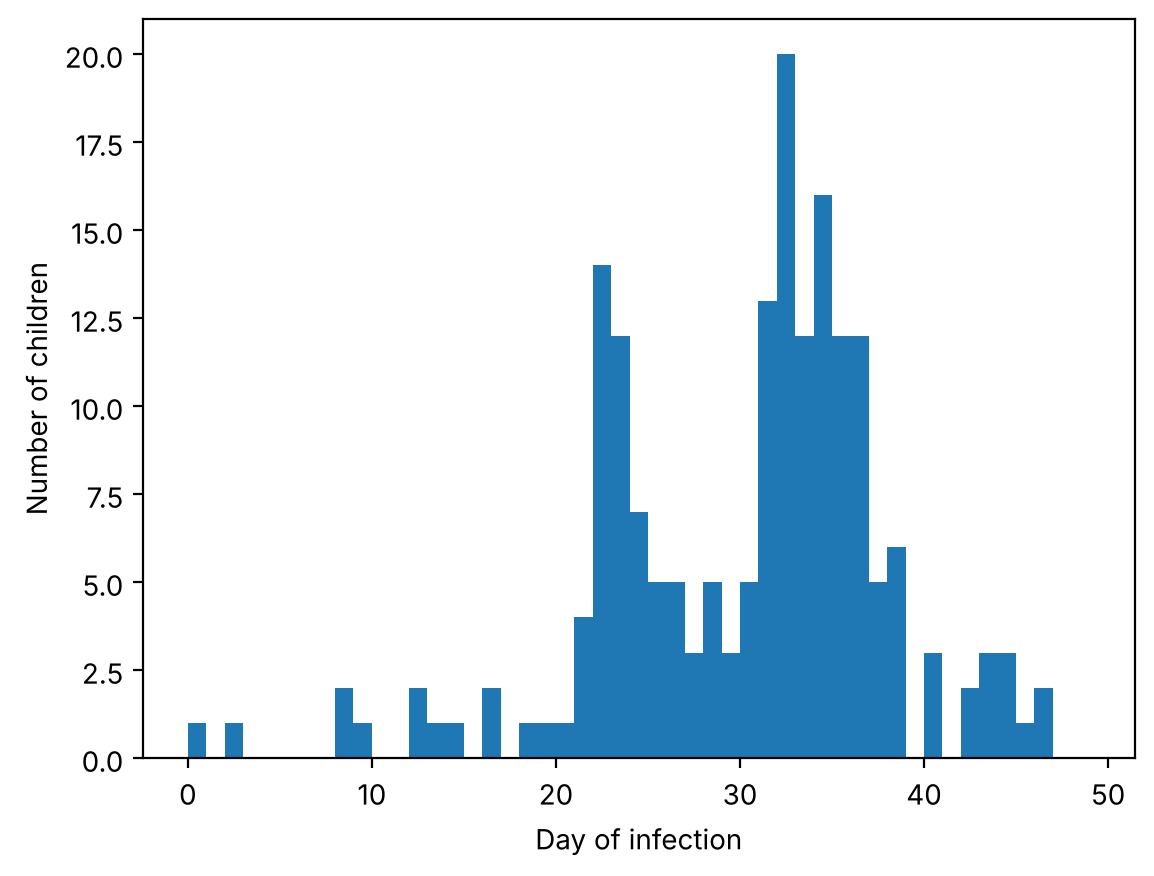

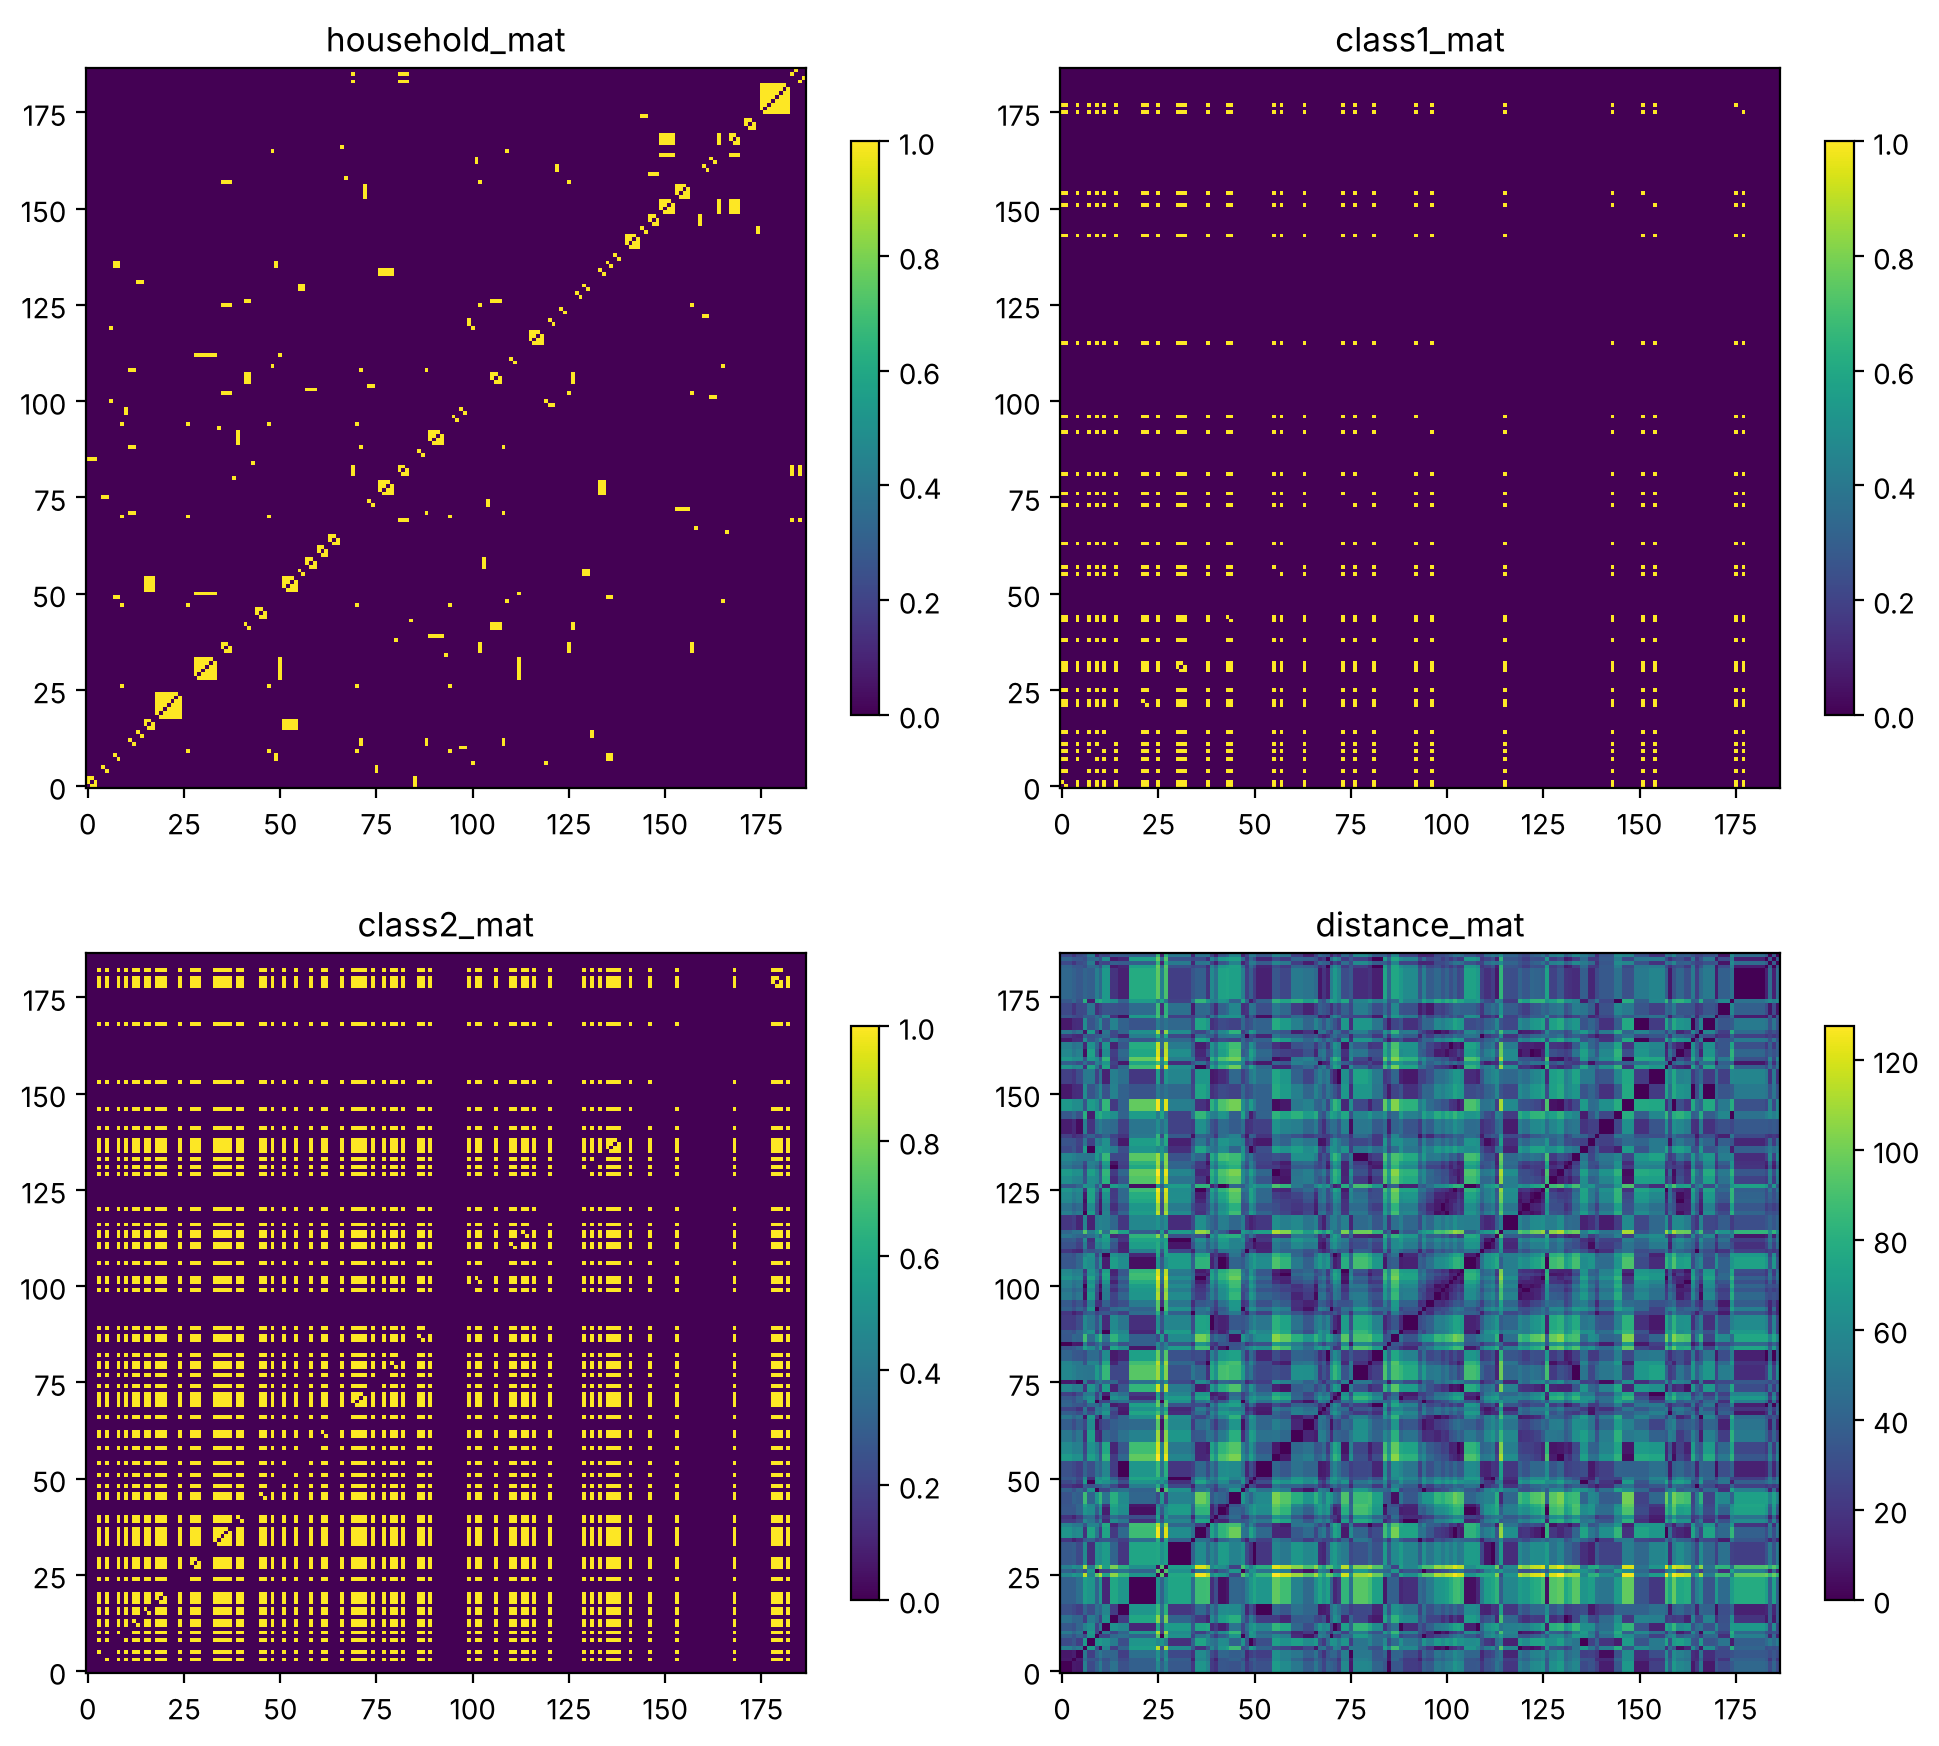

In [5]:
plt.hist(hagelloch["si_time"], bins=range(0, 50))
plt.xlabel("Day of infection")
plt.ylabel("Number of children")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for name, ax in zip(["household_mat", "class1_mat", "class2_mat", "distance_mat"], axes.flatten()):
    im = ax.imshow(hagelloch[name], origin="lower")
    ax.set_title(name)
    fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
plt.show()

The infections span about 46 days, with a single child infected on day 0.

The household matrix is mostly zeros, with small blocks of ones along the diagonal: each block is one household, and the children are listed household by household.  The class matrices have a few large blocks, one per class, because many children share a class.  The distance matrix is "full": every pair of houses is some distance apart.

````{solution-end}
````

### From a line list to an event array

The dataset is in the form of a **line list**: one row per individual, with the time of each of their events.  `gemlib`'s `DiscreteTimeStateTransitionModel` instead wants an **event array** of shape `[T, N, R]`: for each of `T` days and `N` individuals, the number of each of the `R = 2` transitions (S→I and I→R) that happened.  Because each individual here is a single child, every entry is 0 or 1.  This is exactly the format of the `events` that `sample()` returned in the `gemlib` workshop, with one "unit" per child.

The recipe:

1. make an array of zeros of shape `[T + 1, N, 2]`;
2. put a 1 at position `[si_time[n], n, 0]` and `[ir_time[n], n, 1]` for each child `n`;
3. drop day 0.  The first infection is what starts the epidemic, so rather than model it, we _condition_ on it: it goes into the **initial conditions** instead, the state of every child just before day 1.

Step 2 uses a NumPy trick: indexing an array with several arrays of positions at once sets all those elements in one go, like `events[cbind(t, n, 1)] <- 1` in R.

In [6]:
num_individuals = hagelloch["si_time"].shape[0]
max_time = int(hagelloch["ir_time"].max())
everyone = np.arange(num_individuals)      # 0, 1, ..., 186

# An empty [time, individual, transition] array
events = np.zeros((max_time + 1, num_individuals, 2))

# Put a 1 at [infection time, individual, 0] and [removal time, individual, 1]
events[hagelloch["si_time"], everyone, 0] = 1.0   # S->I events
events[hagelloch["ir_time"], everyone, 1] = 1.0   # I->R events

# Drop day 0: we condition on the first infection, which starts the epidemic
events = events[1:]
num_steps = events.shape[0]

# The state of each individual just before day 1: one row per child, columns S, I, R
initial_conditions = np.zeros((num_individuals, 3))
initial_conditions[:, 0] = 1.0                                # everyone susceptible...
index_case = np.where(hagelloch["si_time"] == 0)[0]
initial_conditions[index_case, :] = [0.0, 1.0, 0.0]           # ...except the index case

print("Event array shape [T, N, R]:", events.shape)
print("Index case:", index_case)

Event array shape [T, N, R]: (54, 187, 2)
Index case: [182]


Adding up over individuals (the middle axis, `axis=1`) gives the number of each event per day.  The helper function `plot_incidence` plots this for us:

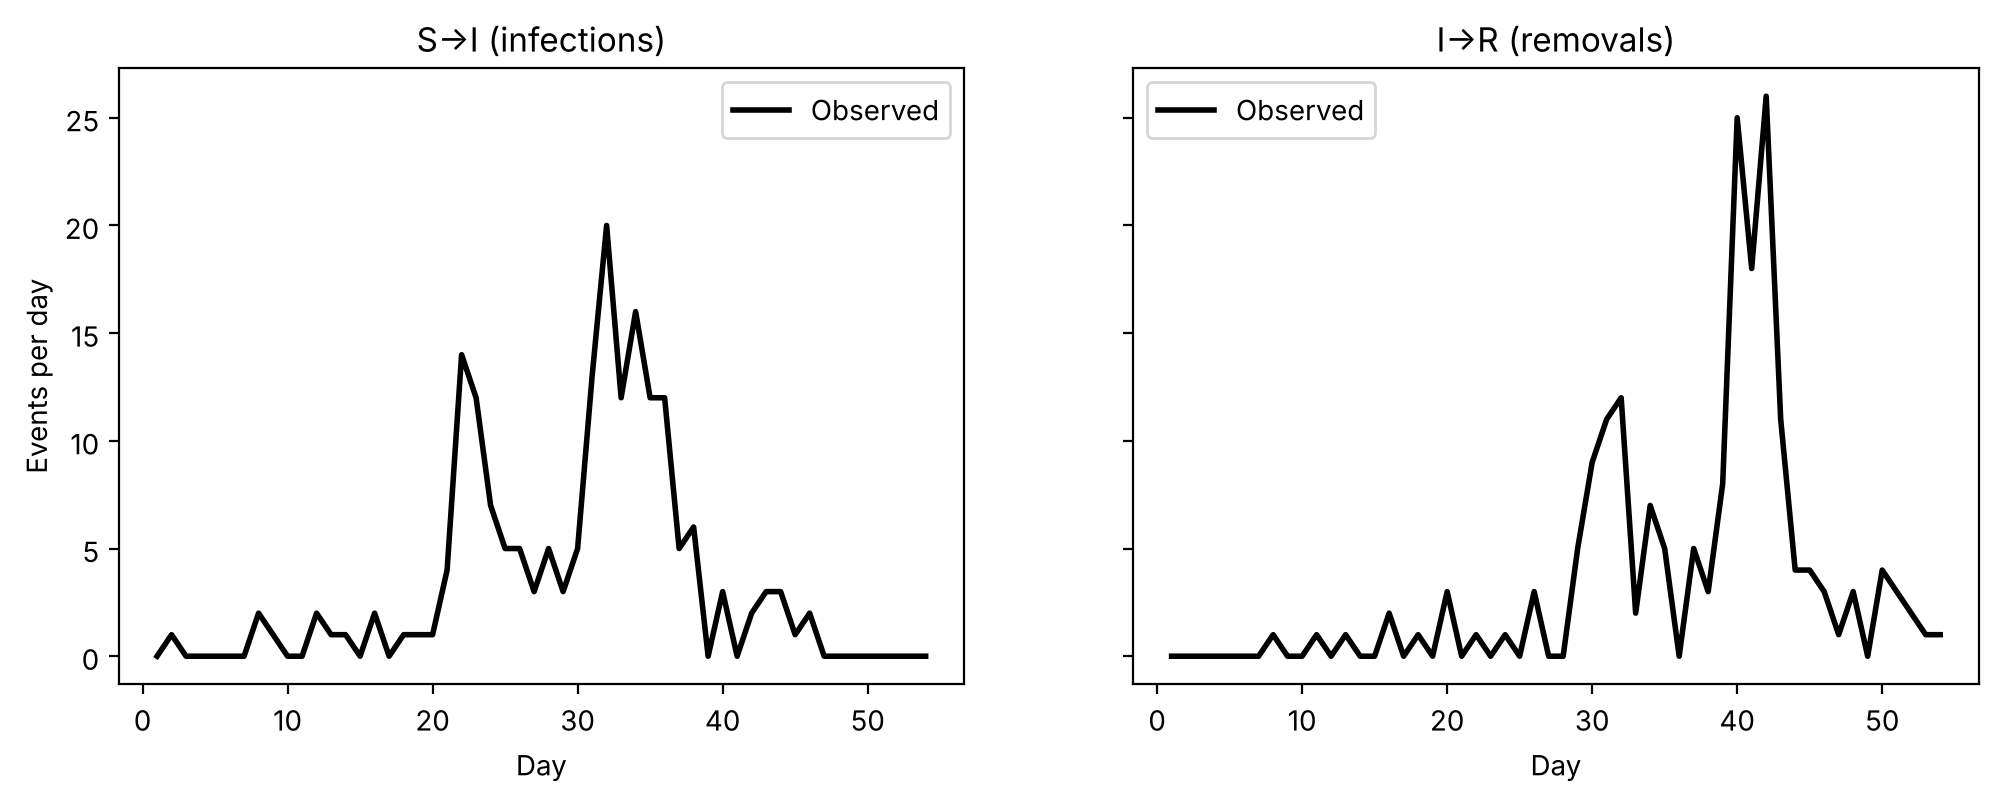

In [7]:
plot_incidence(events)


----

## Part 2: A network epidemic model in `gemlib`

We'll build a discrete-time version of the model of [Neal and Roberts (2004)](https://doi.org/10.1093/biostatistics/5.2.249).  It is an SIR model in which **each child is its own unit**, so the state $x_t$ has one row per child, with a 1 in the column for the state (S, I or R) that child is in.

### Transition rates on a network

In the `gemlib` workshop, the force of infection on a unit was a weighted sum of the infection in the other units, $\sum_j c_{ij}\pi_{jt}$, computed with the matrix product `connectivity @ prev`.  Here we do exactly the same, with individuals as units.  The rate at which susceptible child $i$ becomes infected is

$$
\lambda^{SI}_i(t, x_t) = \sum_{j=1}^{N} w_{ij}\, x^{I}_{jt},
$$

where $x^I_{jt}$ is 1 if child $j$ is infectious on day $t$ (and 0 otherwise), and $w_{ij}$ is the strength of the connection between $i$ and $j$:

$$
w_{ij} = \beta_1 \left[M_h\right]_{ij} + \beta_2 \left[M_{c1}\right]_{ij} + \beta_3 \left[M_{c2}\right]_{ij} + \beta_4\, e^{-\delta\left(\left[M_d\right]_{ij} - \kappa\right)}.
$$

In words: child $i$ picks up infection at rate $\beta_1$ from each infectious child in their household, $\beta_2$ from each infectious classmate in class 1, $\beta_3$ from each in class 2, and from _every_ infectious child in the village at a rate $\beta_4 e^{-\delta(d_{ij}-\kappa)}$ that decays with the distance $d_{ij}$ between their houses.  In matrix form, the vector of infection rates for all children at once is $\lambda^{SI}(t, x_t) = W x^I_t$, which in Python is `W @ state[:, 1]`.

Removal happens at a constant rate, $\lambda^{IR}_i(t, x_t) = \gamma$, so the mean infectious period is $1/\gamma$ days.  As usual in `gemlib`'s discrete-time models, each susceptible child is infected during a day with probability $1 - e^{-\lambda^{SI}_i(t, x_t)\,\delta t}$, with $\delta t = 1$ day.

```{note}
$\kappa$ is a centring constant.  Without it, the posterior distributions of $\beta_4$ and $\delta$ are strongly correlated, which makes MCMC slow.  There's no formula for choosing $\kappa$; it's chosen by experiment, and we use $\kappa = 30$.
```

### The model in code

We put the model inside a function, `hagelloch_sir`, that builds it for given parameter values.  We'll need this when we come to MCMC, which has to rebuild the model every time it tries new parameter values.  The parameters are named after the route of transmission: `household` ($\beta_1$), `class1` ($\beta_2$), `class2` ($\beta_3$), `distance` ($\beta_4$), `spatial_decay` ($\delta$) and `removal_rate` ($\gamma$).

In [8]:
# Connectivity matrices from the dataset
M_household = hagelloch["household_mat"].values
M_class1 = hagelloch["class1_mat"].values
M_class2 = hagelloch["class2_mat"].values
M_distance = hagelloch["distance_mat"].values
kappa = 30.0   # centring constant for distance

sir_incidence_matrix = np.array([
    # SI  IR
    [-1,  0],   # S
    [ 1, -1],   # I
    [ 0,  1],   # R
])


def hagelloch_sir(household, class1, class2, distance, spatial_decay, removal_rate,
                  initial_conditions, name="sir"):
    "Build the Hagelloch network SIR model for given parameter values."

    def si_rate(t, state):
        contact = (
            household * M_household
            + class1 * M_class1
            + class2 * M_class2
            + distance * jnp.exp(-spatial_decay * (M_distance - kappa))
        )
        return contact @ state[:, 1]   # weighted number of infectious contacts of each child

    def ir_rate(t, state):
        return removal_rate

    return gld.DiscreteTimeStateTransitionModel(
        transition_rate_fn=[si_rate, ir_rate],
        incidence_matrix=sir_incidence_matrix,
        initial_state=initial_conditions,
        num_steps=num_steps,
        name=name,
    )

Let's build the model with some plausible parameter values and simulate 20 epidemics from it.  (These values are roughly what we'll estimate later; in real life you'd need to experiment to find sensible values.)

In [9]:
sir_model = hagelloch_sir(
    household=0.01, class1=0.04, class2=0.01, distance=0.001, spatial_decay=0.01,
    removal_rate=0.14, initial_conditions=initial_conditions,
)

sim_events = sir_model.sample(sample_shape=20, seed=jax.random.key(42))
print("Simulated events [simulations, T, N, R]:", sim_events.shape)

Simulated events [simulations, T, N, R]: (20, 54, 187, 2)


````{exercise-start}
:label: hagelloch-ex2
````

1. Use `plot_incidence(events, sim_events)` to compare the simulated epidemics with the observed one.
2. Compute the state of every child on every day with `sim_states = sir_model.compute_state(sim_events)`, and plot the number of children in S, I and R with `plot_states(sim_states, alpha=0.3)`.
3. **What if the school had closed?**  Build a second model with `class1=0.0` and `class2=0.0`, simulate 20 epidemics from it, and compare the final number of children infected with and without school transmission.

```{hint}
The final number infected in each simulation is the number in R at the last time step: `sim_states[:, -1, :, 2].sum(axis=-1)` picks out the last day (`-1`), all children (`:`), the R column (`2`), and adds up over children.
```

In [22]:
# your code here

````{exercise-end}
````

````{solution-start} hagelloch-ex2
:class: dropdown
````

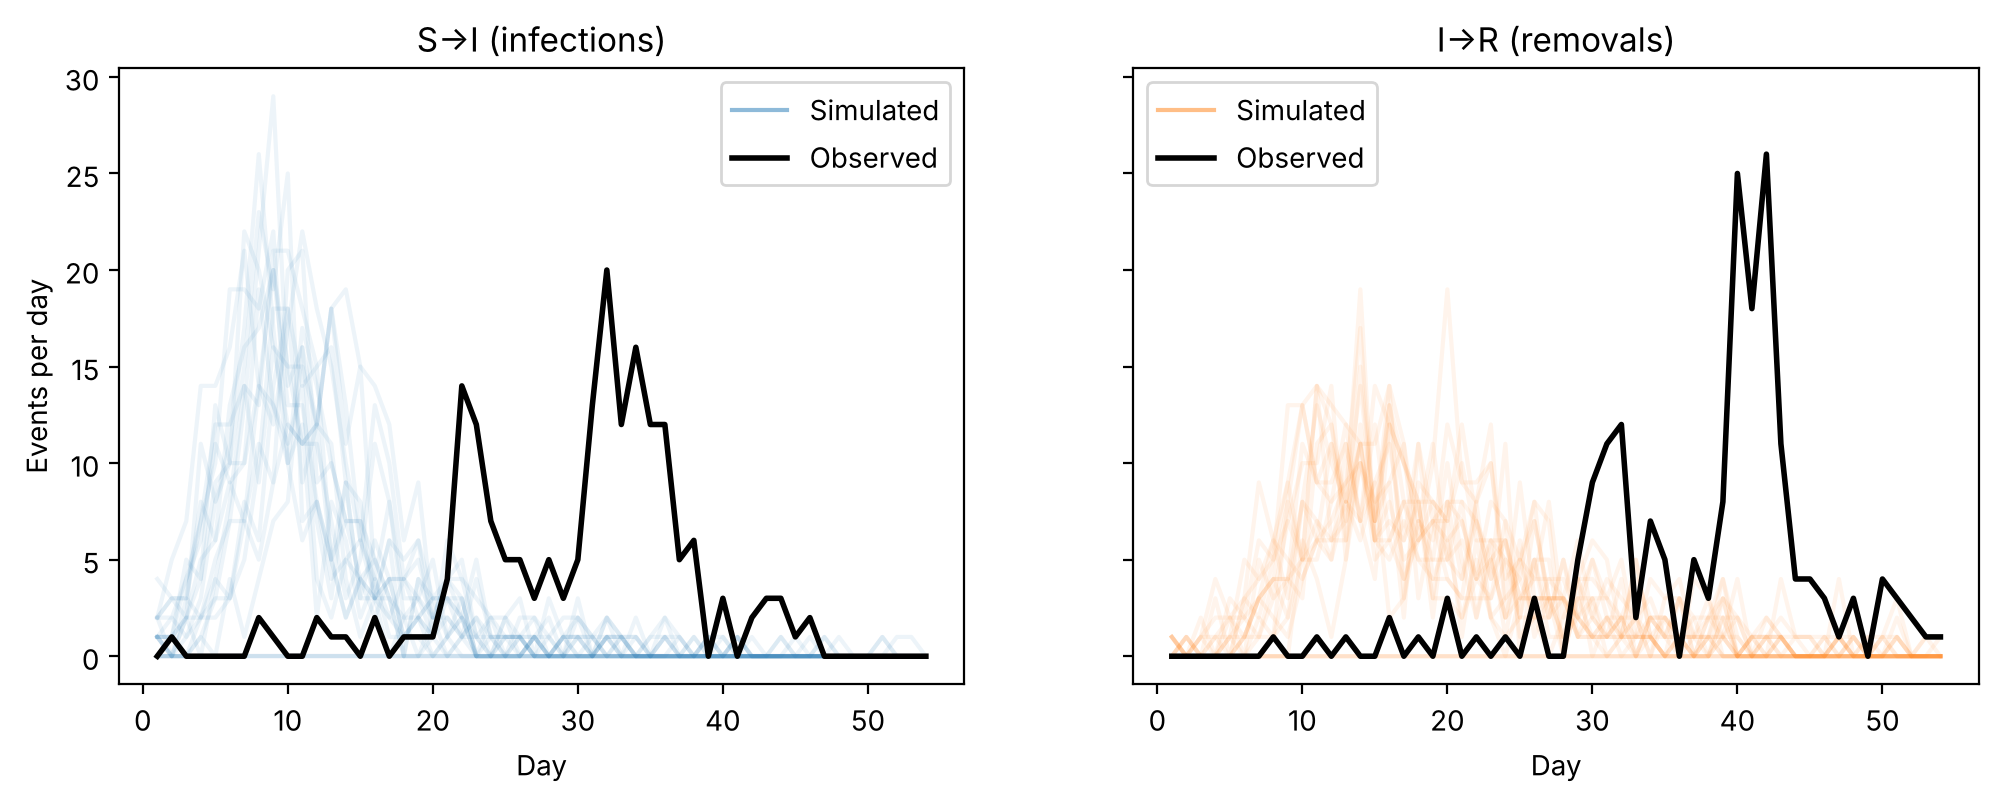

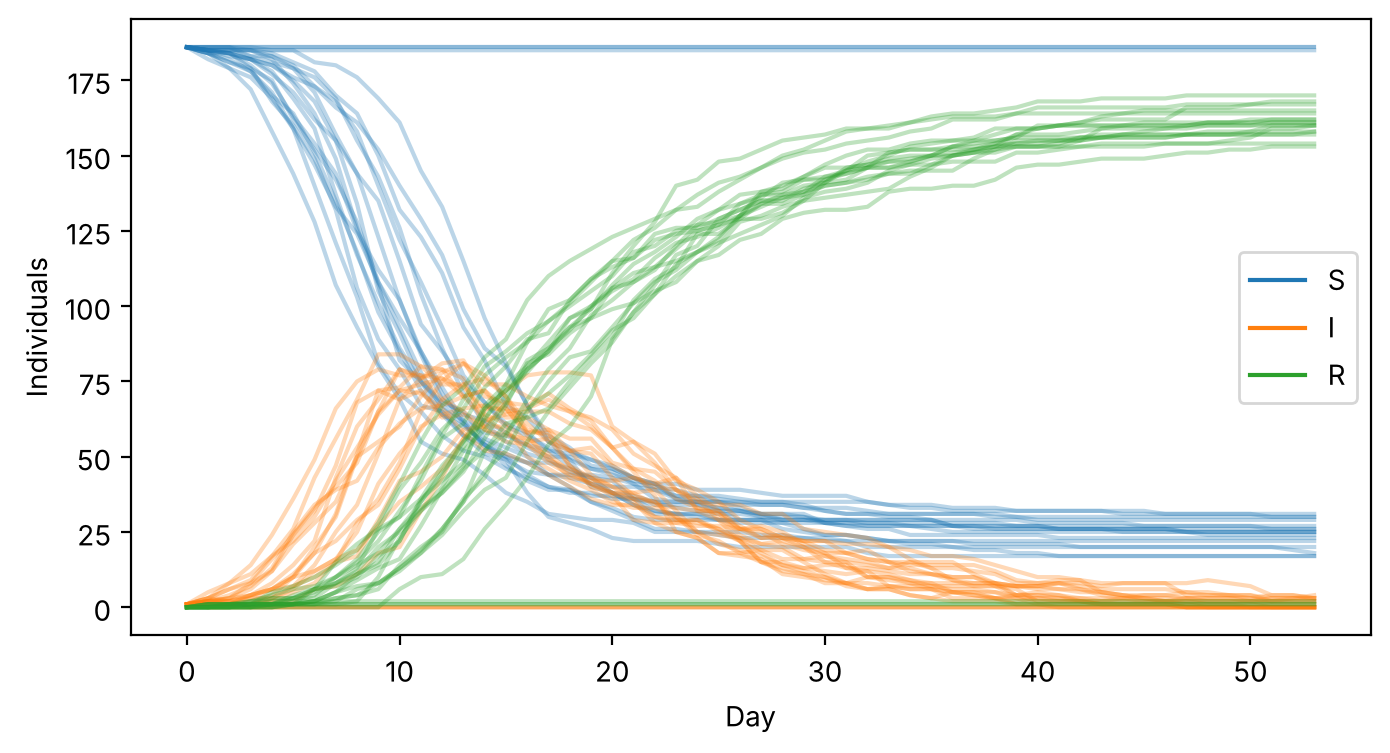

In [11]:
plot_incidence(events, sim_events)

sim_states = sir_model.compute_state(sim_events)
plot_states(sim_states, alpha=0.3)

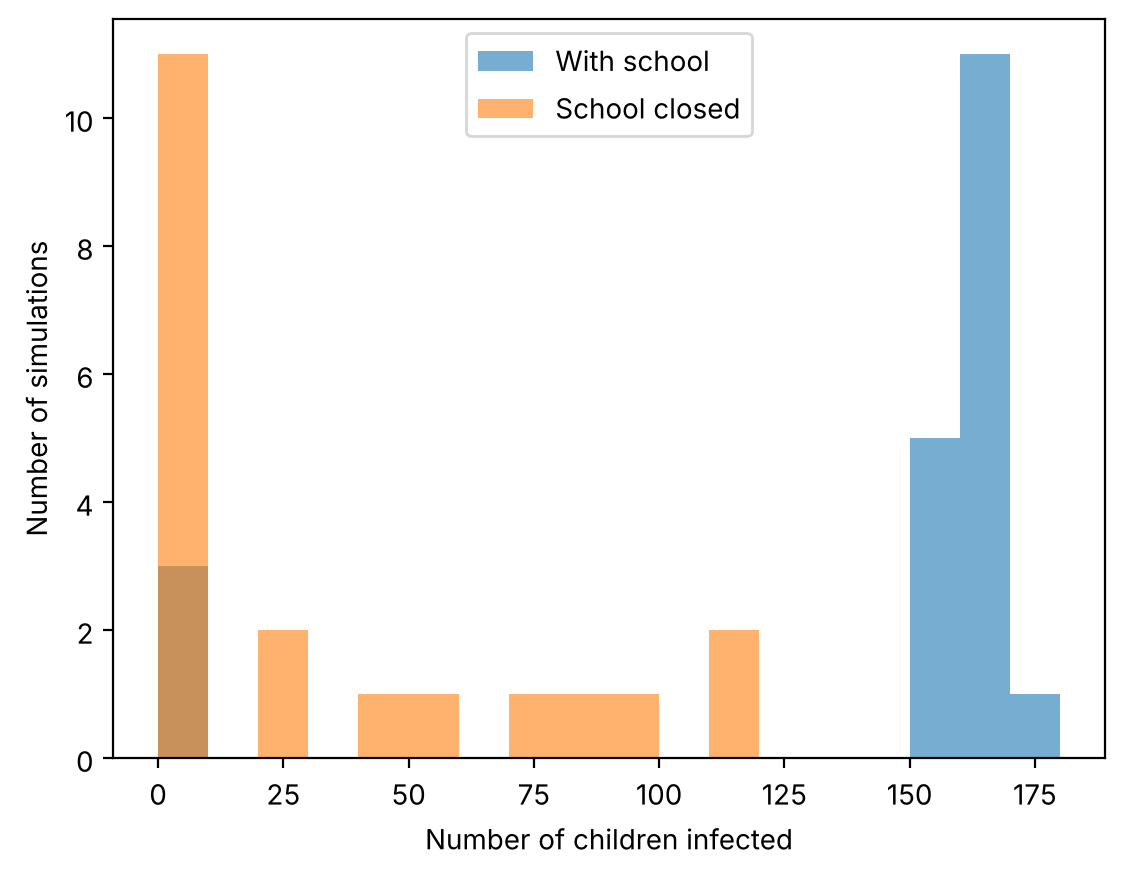

In [12]:
no_school_model = hagelloch_sir(
    household=0.01, class1=0.0, class2=0.0, distance=0.001, spatial_decay=0.01,
    removal_rate=0.14, initial_conditions=initial_conditions,
)
no_school_states = no_school_model.compute_state(
    no_school_model.sample(sample_shape=20, seed=jax.random.key(42))
)

final_size = sim_states[:, -1, :, 2].sum(axis=-1)
final_size_no_school = no_school_states[:, -1, :, 2].sum(axis=-1)

plt.hist(final_size, bins=range(0, 190, 10), alpha=0.6, label="With school")
plt.hist(final_size_no_school, bins=range(0, 190, 10), alpha=0.6, label="School closed")
plt.xlabel("Number of children infected")
plt.ylabel("Number of simulations")
plt.legend()
plt.show()

With these parameter values, closing the school makes a big difference.  With school transmission, almost every simulated epidemic infects 150 or more children; without it, most fizzle out with only a handful of cases, and the rest infect far fewer.  Of course, that depends on the parameter values we made up: to answer the question properly we need to estimate them from the data, which is what the rest of the workshop does.

````{solution-end}
````

### The likelihood

As in the `gemlib` and likelihood workshops, `log_prob` gives the log-likelihood: the log-probability of an event array under the model.  For the observed epidemic, it is a sum of Binomial (here Bernoulli, since each unit is one child) log-probabilities, one for each transition, child and day, just as for the SIR model in the likelihood workshop.  We can use it to compare how well different parameter values explain the data:

In [13]:
school_closed_model = hagelloch_sir(
    household=0.01, class1=0.0, class2=0.0, distance=0.001, spatial_decay=0.01,
    removal_rate=0.14, initial_conditions=initial_conditions,
)
print("Log-likelihood with the values above:", sir_model.log_prob(events))
print("Log-likelihood with no school transmission:", school_closed_model.log_prob(events))

Log-likelihood with the values above: -1201.5310206906163
Log-likelihood with no school transmission: -1251.5142596923995


The data are far better explained by a model with school transmission.  Rather than comparing a few hand-picked values, we now let MCMC explore all the parameter values that are consistent with the data.

----

## Part 3: A Bayesian model

To do Bayesian inference we need a joint probability model for the parameters and the data, which means adding priors.  All the parameters are positive rates, so we give them Exponential priors:

\begin{align*}
\beta_1, \beta_2, \beta_3, \beta_4 & \sim \operatorname{Exponential}(10) \\
\delta & \sim \operatorname{Exponential}(20) \\
\gamma & \sim \operatorname{Exponential}(10) \\
x_{i,0} & \sim \operatorname{Multinomial}(1, (0.99, 0.01, 0)), \quad i = 1, \dots, N \\
Z & \sim \operatorname{SIR}(\beta_1, \beta_2, \beta_3, \beta_4, \delta, \gamma, x_0).
\end{align*}

The initial state of each child is also treated as random: each child independently starts susceptible with probability 0.99 or infectious with probability 0.01.  (We'll need this in the next workshop, when we're no longer sure who the index case was.)

```{mermaid}
:name: hagelloch-dag
:alt: Bayesian DAG for the Hagelloch model
:caption: Bayesian DAG for the Hagelloch model

---
config:
  look: handDrawn
  theme: neutral
---

flowchart TD
  B1((β₁)) --> STM((SIR))
  B2((β₂)) --> STM
  B3((β₃)) --> STM
  B4((β₄)) --> STM
  D((δ)) --> STM
  G((γ)) --> STM
  X0((x₀)) --> STM
```

As in the Bayes and MCMC workshop, we write this as a `JointDistributionCoroutineAutoBatched`, reading each `yield` as "$\sim$".  The `np.float64(...)` makes sure everything is computed in double precision.

In [14]:
@tfd.JointDistributionCoroutineAutoBatched
def joint_model():
    household = yield tfd.Exponential(np.float64(10.0), name="household")
    class1 = yield tfd.Exponential(np.float64(10.0), name="class1")
    class2 = yield tfd.Exponential(np.float64(10.0), name="class2")
    distance = yield tfd.Exponential(np.float64(10.0), name="distance")
    spatial_decay = yield tfd.Exponential(np.float64(20.0), name="spatial_decay")
    removal_rate = yield tfd.Exponential(np.float64(10.0), name="removal_rate")

    # Each child independently starts S (prob 0.99) or I (prob 0.01)
    initial_conditions = yield tfd.Sample(
        tfd.Multinomial(1, probs=np.array([0.99, 0.01, 0.0])),
        sample_shape=num_individuals,
        name="initial_conditions",
    )

    yield hagelloch_sir(household, class1, class2, distance, spatial_decay, removal_rate,
                        initial_conditions, name="sir")

A quick check that the model works: draw parameters from the prior and simulate an epidemic from them.

In [15]:
prior_draw = joint_model.sample(seed=jax.random.key(1))
print("household:", prior_draw.household, " removal_rate:", prior_draw.removal_rate)
print("Epidemic shape:", prior_draw.sir.shape)

household: 0.08520047776714457  removal_rate: 0.06694910130151117
Epidemic shape: (54, 187, 2)


----

## Part 4: MCMC, assuming the infection times are known

### Conditioning on the data

For now, we assume we know every child's infection and removal times, and hence also the initial conditions.  As in the Bayes and MCMC workshop, we **condition** on the data by pinning the `sir` and `initial_conditions` variables to their observed values.  The pinned model's `log_prob` is then the unnormalised log posterior, a function of the six parameters only.

MCMC needs a starting point at which the log posterior is finite (otherwise every proposal looks infinitely better, or worse, than where we are).  We take a draw from the model and replace the parameter values with sensible starting values.

In [16]:
conditioned_model = joint_model.experimental_pin(sir=events, initial_conditions=initial_conditions)

initial_position = conditioned_model.sample_unpinned(seed=jax.random.key(0))._replace(
    household=0.01, class1=0.04, class2=0.01, distance=0.001, spatial_decay=0.01, removal_rate=0.14
)
print(initial_position)
print("Log posterior at the starting point:", conditioned_model.log_prob(initial_position))

StructTuple(
  household=0.01,
  class1=0.04,
  class2=0.01,
  distance=0.001,
  spatial_decay=0.01,
  removal_rate=0.14
)


Log posterior at the starting point: -1195.7068956068315


### A Metropolis-within-Gibbs sampler

In the Bayes and MCMC workshop, one random walk Metropolis-Hastings (RWMH) step updated both parameters at once.  With six parameters on very different scales, it's hard to choose a single step size that suits them all.  Instead, we update **one parameter at a time**, each with its own RWMH step and its own step size, and cycle through them.  This is called **Metropolis-within-Gibbs**: each step targets the posterior of one parameter _given the current values of all the others_.

Each parameter must be positive, so we take the random walk on the **log scale**: propose $\log\theta' = \log\theta + \varepsilon$, $\varepsilon \sim \operatorname{Normal}(0, s^2)$, i.e. $\theta' = \theta e^{\varepsilon}$.  Proposals are always positive, and the step size $s$ is now a _relative_ step: $s = 0.5$ means steps of roughly ±50%, whatever the size of the parameter.  This is the same trick as optimising over $\log\gamma$ in the likelihood workshop.

In `gemlib`, three pieces fit together:

- `mcmc.rwmh(scale=s)` is the random walk step;
- `mcmc.transform_sampling_algorithm(bijectors=tfb.Exp(), ...)` makes it walk on the log scale (the parameter is $\exp$ of the thing being walked on);
- `mcmc.MwgStep(..., target_names="household")` applies it to just one named parameter.

The `>>` operator chains steps together, so that one MCMC iteration does each step in turn.

In [17]:
def log_rwmh(param_name, scale):
    "A random walk Metropolis-Hastings step for one parameter, on the log scale."
    return mcmc.MwgStep(
        mcmc.transform_sampling_algorithm(
            bijectors=tfb.Exp(),
            sampling_algorithm=mcmc.rwmh(scale=scale),
        ),
        target_names=param_name,
    )


param_kernel = (
    log_rwmh("household", 0.5)
    >> log_rwmh("class1", 0.5)
    >> log_rwmh("class2", 0.5)
    >> log_rwmh("distance", 0.4)
    >> log_rwmh("spatial_decay", 1.2)
    >> log_rwmh("removal_rate", 0.25)
)

Now we run the sampler for 5000 iterations.  Wrapping the call in `jax.jit` compiles it, which makes it much faster.  It takes a minute or two.

In [ ]:
@jax.jit
def run_sampler(seed):
    return mcmc.mcmc(
        num_samples=5000,
        sampling_algorithm=param_kernel,
        target_log_density_fn=conditioned_model.log_prob,
        initial_position=initial_position,
        seed=seed,
    )

samples, info = run_sampler(jax.random.key(42))

`samples` holds the 5000 draws of each parameter, e.g. `samples.household`.  `info` is a list with one entry per step in `param_kernel`, in order; for example, `info[0].is_accepted` records whether each `household` proposal was accepted.

````{exercise-start}
:label: hagelloch-ex3
````

Check the MCMC run.

1. Compute the acceptance rate of each of the six steps.  (Hint: loop over `PARAM_NAMES` and `info` together, and use `np.mean(...)`.)  For a single-parameter random walk, around 0.44 is ideal.
2. Draw trace plots, posterior histograms and autocorrelation plots with `trace_plots(samples, burn_in=1000)`.
3. Print a summary with `summarise(samples, burn_in=1000)`.  The final column is the **effective sample size** (ESS): roughly, how many _independent_ draws our 4000 correlated post-burn-in draws are worth.
4. Are you happy with the run?

In [22]:
# your code here

````{exercise-end}
````

````{solution-start} hagelloch-ex3
:class: dropdown
````

In [20]:
for name, step_info in zip(PARAM_NAMES, info):
    print(f"Acceptance rate for {name}: {np.mean(step_info.is_accepted):.2f}")

Acceptance rate for household: 0.44
Acceptance rate for class1: 0.44
Acceptance rate for class2: 0.48
Acceptance rate for distance: 0.39
Acceptance rate for spatial_decay: 0.58
Acceptance rate for removal_rate: 0.33


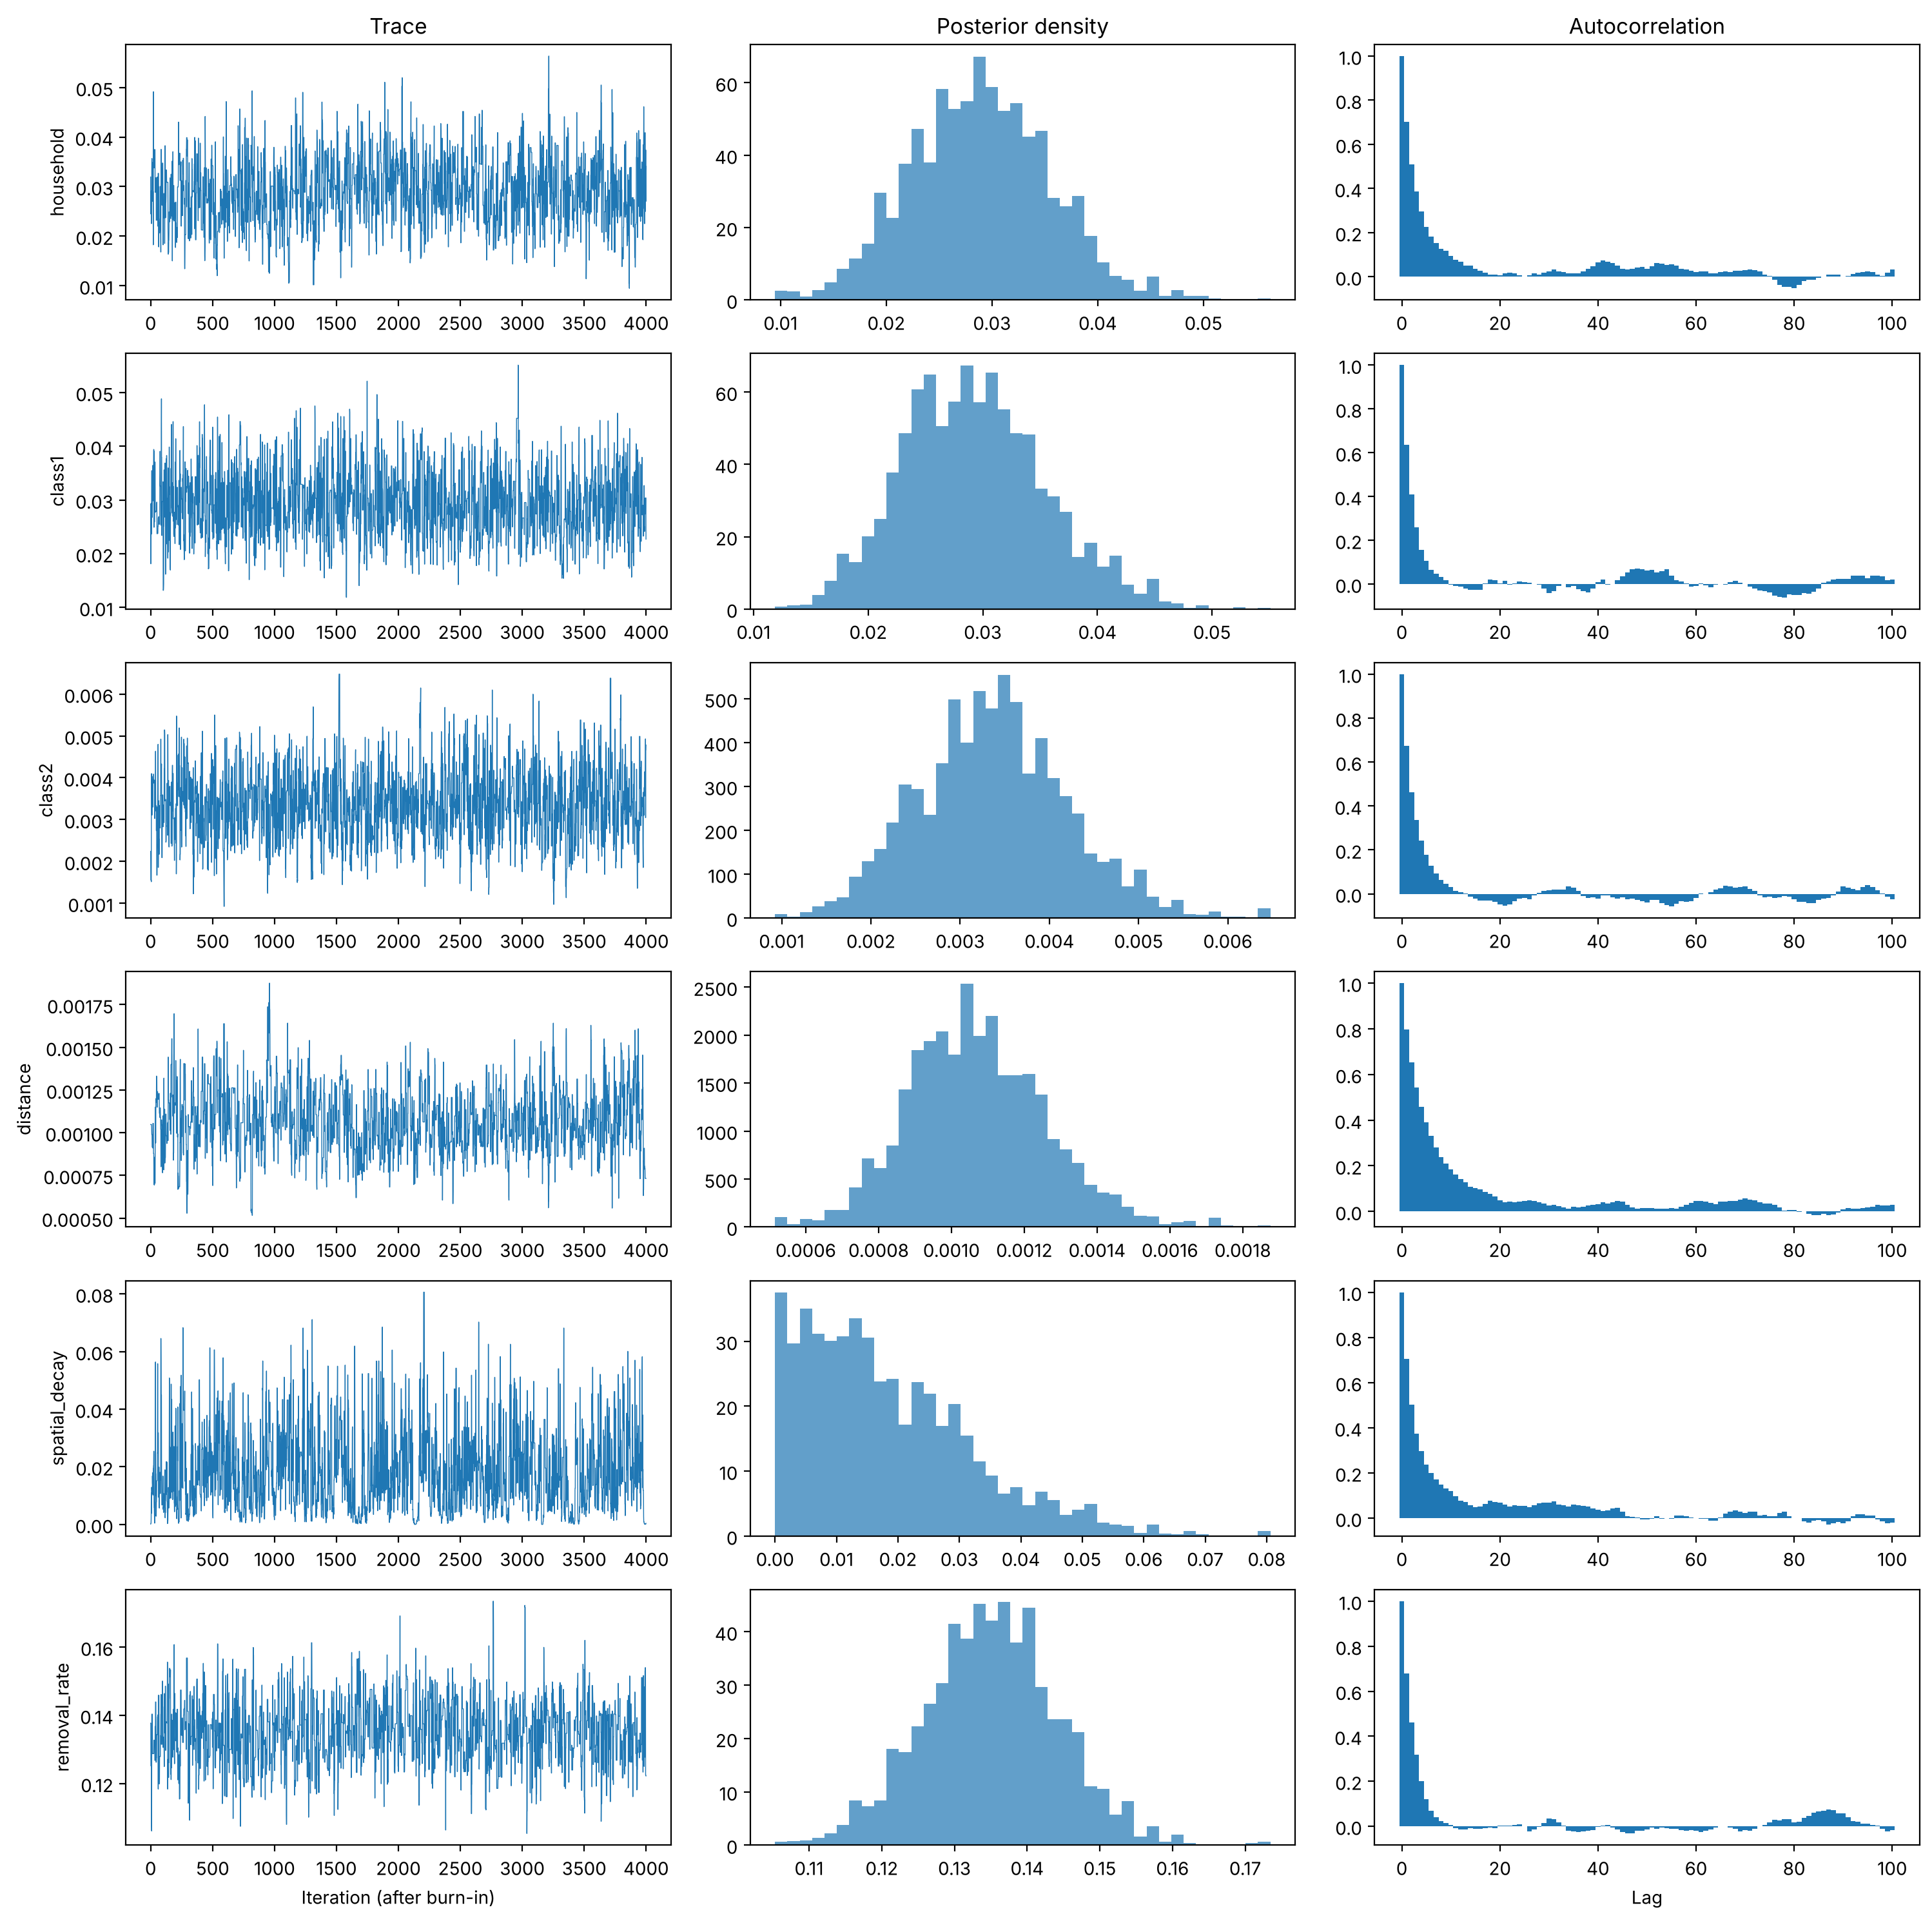

parameter            mean      2.5%     97.5%     ESS


household          0.0289    0.0164    0.0423     377
class1             0.0293    0.0179    0.0423     898
class2             0.0034    0.0018    0.0051     722
distance           0.0011    0.0007    0.0015     270
spatial_decay      0.0184    0.0006    0.0518     371
removal_rate       0.1351    0.1164    0.1535     824


In [21]:
trace_plots(samples, burn_in=1000)
summarise(samples, burn_in=1000)

The acceptance rates are reasonably close to 0.44, the trace plots look like "hairy caterpillars" with no trends, and the autocorrelation dies away within a few tens of iterations.  The effective sample sizes are in the hundreds, which is enough for posterior means and rough credible intervals, though a longer run would be better for a paper.  Updating one parameter at a time is simple but not especially efficient; gradient-based samplers such as `gemlib.mcmc.adaptive_hmc` can do better.

````{solution-end}
````

````{exercise-start}
:label: hagelloch-ex4
````

Interpret the results.

1. Which route of transmission has the highest rate per infectious contact: household, class 1 or class 2?  Do the credible intervals overlap?
2. Each rate is _per infectious contact_.  Use `M_household.sum(axis=1).mean()`, and the same for the class matrices, to find how many household and classmate contacts the average child has.  Why might household transmission matter less overall than its per-contact rate suggests?
3. Compute the posterior distribution of the mean infectious period $1/\gamma$ (in days) and give a 95% credible interval.

In [22]:
# your code here

````{exercise-end}
````

````{solution-start} hagelloch-ex4
:class: dropdown
````

**1.** In the summary table, the household and class 1 rates are very similar, at around 0.03 per infectious contact per day, with heavily overlapping credible intervals.  The class 2 rate is roughly ten times smaller, and its credible interval doesn't overlap with the other two.

**2.**

In [23]:
for name, M_ in [("household", M_household), ("class 1", M_class1), ("class 2", M_class2)]:
    print(f"Average number of {name} contacts per child: {M_.sum(axis=1).mean():.1f}")

Average number of household contacts per child: 3.5
Average number of class 1 contacts per child: 4.7
Average number of class 2 contacts per child: 24.4


The average child has about 3.5 household contacts, 4.7 class 1 contacts and 24 class 2 contacts (these averages include the pre-school children, who have no classmates).  The infection pressure from a route is roughly (rate per contact) × (number of infectious contacts by that route), so a small per-contact rate spread over many contacts, as in class 2, can matter as much as a large rate over a few contacts, as in the household.  Per-contact rates alone don't tell us which route caused the most infections.

**3.**

In [24]:
infectious_period = 1.0 / np.asarray(samples.removal_rate)[1000:]
lo, hi = np.quantile(infectious_period, [0.025, 0.975])
print(f"Mean infectious period: {infectious_period.mean():.1f} days (95% CrI {lo:.1f} to {hi:.1f})")

Mean infectious period: 7.4 days (95% CrI 6.5 to 8.6)


````{solution-end}
````

----

## Part 5: Checking the fit

A good way to check a fitted model is to simulate from it, and see whether the simulations look like the data.  The **posterior predictive distribution** does this while accounting for our uncertainty about the parameters: for each of a set of posterior samples, we simulate an epidemic using _those_ parameter values.

We take every 40th sample after burn-in (100 samples in all), and simulate one epidemic for each, starting from the observed initial conditions.  `jax.vmap` turns a function that simulates one epidemic into one that simulates for a whole array of parameter values at once, a bit like `mapply` in R but much faster.

Posterior predictive events: (100, 54, 187, 2)


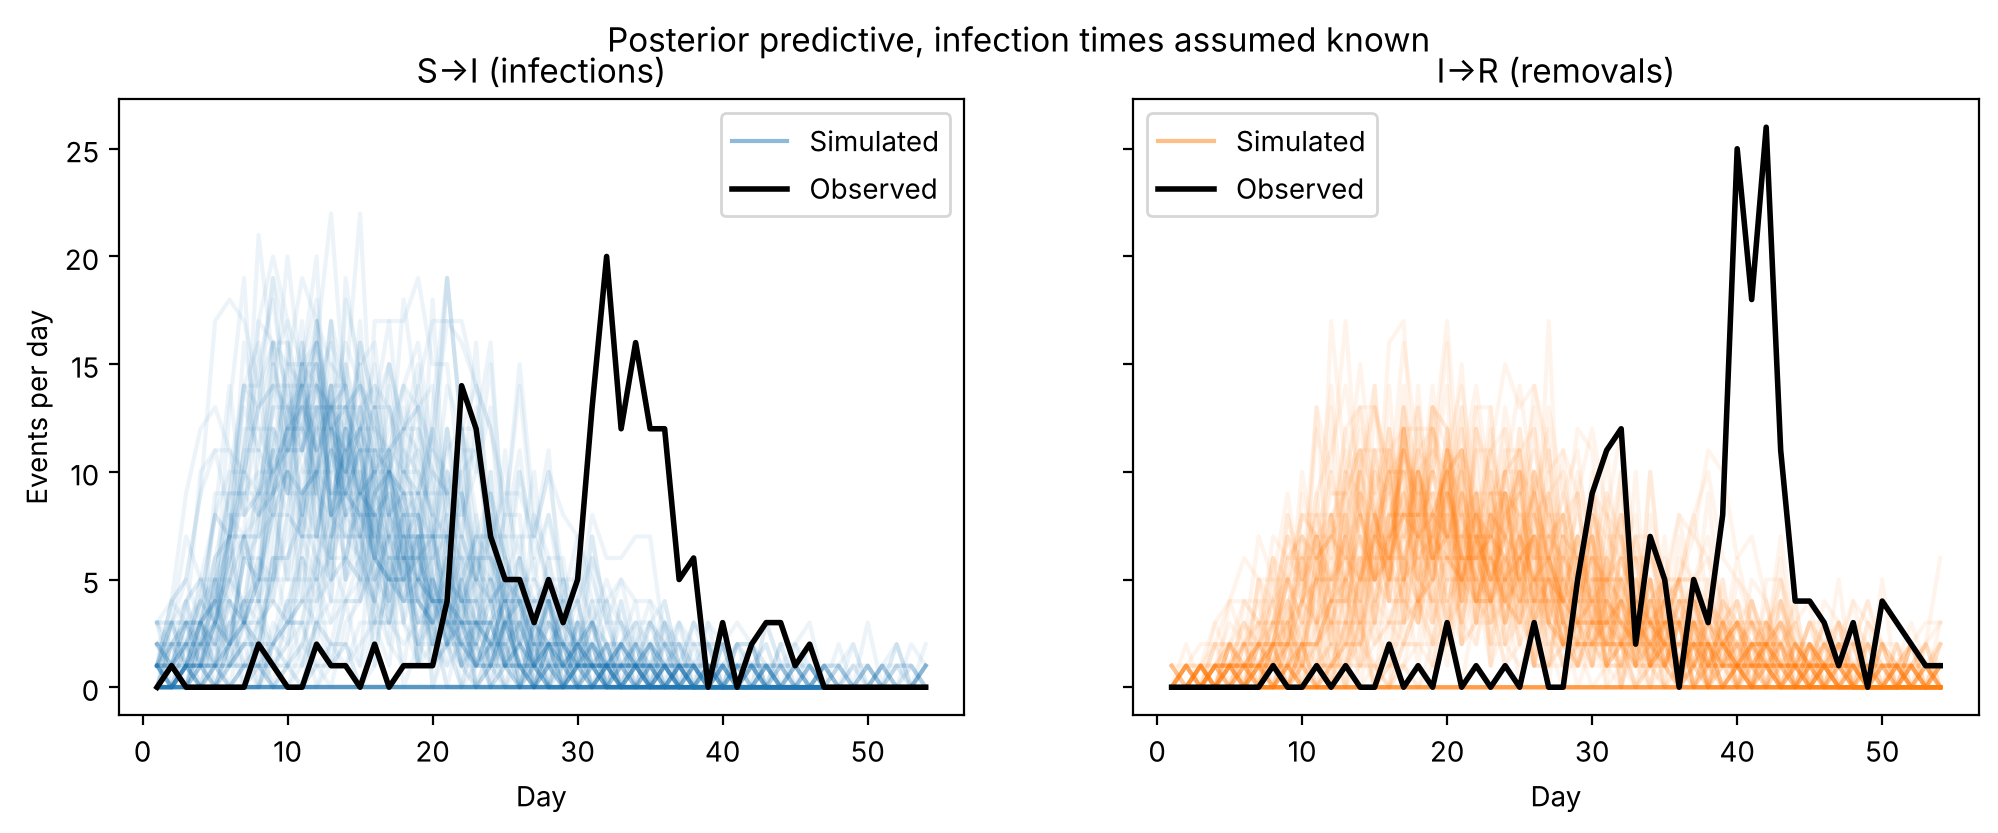

In [25]:
thinned = jax.tree.map(lambda x: x[1000::40], samples)   # every 40th sample after burn-in
num_draws = thinned.household.shape[0]


def simulate_one(household, class1, class2, distance, spatial_decay, removal_rate, seed):
    model = hagelloch_sir(household, class1, class2, distance, spatial_decay, removal_rate,
                          initial_conditions)
    return model.sample(seed=seed)


predictive_events = jax.vmap(simulate_one)(
    thinned.household, thinned.class1, thinned.class2, thinned.distance,
    thinned.spatial_decay, thinned.removal_rate,
    jax.random.split(jax.random.key(44), num_draws),
)
print("Posterior predictive events:", predictive_events.shape)

plot_incidence(events, predictive_events, title="Posterior predictive, infection times assumed known")

````{exercise-start}
:label: hagelloch-ex5
````

1. How well does the posterior predictive distribution capture the observed epidemic?  Look at the timing and height of the peak, and the spread of the simulations.
2. We assumed that the infection times are known.  Thinking about how they were obtained, what might be wrong with this assumption, and how could it affect our estimates?

````{exercise-end}
````

````{solution-start} hagelloch-ex5
:class: dropdown
````

The fit is poor.  The simulated epidemics take off almost straight away and peak around days 10 to 15, whereas in the real outbreak infections stayed low for about three weeks and then came in two waves, peaking around days 22 and 32.  The simulated removals are correspondingly far too early.  The simulations also infect fewer children on average than the 186 actually infected, and a few fizzle out altogether.

The infection times were worked back from symptom dates, probably using a fixed delay, so they're at best approximate.  By fixing them, we force the model to explain a set of infection times that may be wrong, and we ignore our uncertainty about them altogether.  Both can bias the parameter estimates (for example, the infectious periods, and hence $\gamma$, follow directly from the assumed infection times) and make the posterior look more certain than it should.  In the next workshop we'll treat the infection times as unknowns, and estimate them alongside the parameters.

````{solution-end}
````


----

## Wrap-up

Today we have:

- turned a line list of event times into a `gemlib` event array and initial conditions;
- built an individual-level network SIR model, where each child is a unit and the force of infection is a matrix product over household, school and spatial connections;
- simulated "what-if" scenarios, such as closing the school;
- written the model as a Bayesian model and estimated its six parameters with a Metropolis-within-Gibbs sampler using log-scale random walks;
- checked the MCMC run, interpreted the posterior, and used the posterior predictive distribution to check the fit.

### Where next?

We assumed that the infection times were known, but they almost never are.  In the next workshop we'll introduce **data augmentation MCMC**, which treats the missing infection times as extra unknowns and samples them along with the parameters.